# Lecture : Graph-based Visualization

## Lab 07 : Visualization with deep learning features

### Xavier Bresson  


In [ ]:
# For Google Colaboratory
import sys, os
if 'google.colab' in sys.modules:
    # mount google drive
    from google.colab import drive
    drive.mount('/content/gdrive')
    path_to_file = '/content/gdrive/My Drive/CS5284_2026_codes/04_Visualization'
    print(path_to_file)
    # change current path to the folder containing "path_to_file"
    os.chdir(path_to_file)
    !pip install umap-learn
    !pwd
    

In [1]:
# Load libraries
import numpy as np
import scipy.io
from matplotlib import pyplot
import matplotlib.pyplot as plt
import time
import sys; sys.path.insert(0, 'lib/')
import scipy.sparse.linalg
# import scipy.ndimage
from lib.utils import construct_knn_graph, nldr_visualization
import warnings; warnings.filterwarnings("ignore")
import umap
import torch, torchvision
import torchvision.transforms as transforms
import numpy as np
import os.path


# UMAP for CIFAR images embedded with inception features

In [2]:
# CIFAR 
if not os.path.isfile('datasets/cifar.pt'):  # download and prepare CIFAR dataset
    trainset = torchvision.datasets.CIFAR10(root='datasets/', train=True, download=True, transform=transforms.ToTensor())
    print('num_data : ',len(trainset))
    print('data, label : ',trainset[0][0].size(),trainset[0][1])
    train_data = torch.Tensor(50000,3,32,32)
    train_label = torch.LongTensor(50000)
    for idx, data in enumerate(trainset):
        train_data[idx] = data[0]
        train_label[idx] = data[1]
    torch.save([train_data, train_label],'datasets/cifar.pt')
else:
    train_data, train_label = torch.load('datasets/cifar.pt')
    
X, C = train_data, train_label
print('X, C :',X.size(), C.size())
X = X.view(50000,-1).numpy()
C = C.numpy()


X, C : torch.Size([50000, 3, 32, 32]) torch.Size([50000])


# Compute or load 2048-dim inception features

## Question: raw feature vs inception features
Compare the visualization of CIFAR using raw features (lab 6) and the visualization using inception features.

#### 1. What do you observe?

#### 2. What causes the difference?




In [3]:
compute_inception_features = True
compute_inception_features = False
if compute_inception_features:
    
    device = 'cpu'
    def compute_inception_v3_feat(dataset, bs):
        # https://pytorch.org/hub/pytorch_vision_inception_v3
        #model = torch.hub.load('pytorch/vision:v0.10.0', 'inception_v3', pretrained=True)
        model = torchvision.models.inception_v3(weights=torchvision.models.Inception_V3_Weights.DEFAULT) # 100MB
        model.eval().to(device)
        input_transform = transforms.Compose([
            transforms.Resize( size=(299, 299), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True ),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5] ) # rescale [0, 1] to [-1, 1]
            ])
        num_data = dataset.size(0)
        #print('num_data:', num_data, ' num_feat (inception_v3):', 2048)
        data_feat = []
        start = time.time()
        with torch.no_grad():
            for i in range(num_data//bs):
                x = input_transform(dataset[i*bs:(i+1)*bs,:,:,:]) # bs x 3 x 299 x 299
                x = model.Conv2d_1a_3x3(x); x = model.Conv2d_2a_3x3(x); x = model.Conv2d_2b_3x3(x)
                x = model.maxpool1(x); x = model.Conv2d_3b_1x1(x); x = model.Conv2d_4a_3x3(x)
                x = model.maxpool2(x); x = model.Mixed_5b(x); x = model.Mixed_5c(x); x = model.Mixed_5d(x)
                x = model.Mixed_6a(x); x = model.Mixed_6b(x); x = model.Mixed_6c(x); x = model.Mixed_6d(x)
                x = model.Mixed_6e(x); x = model.Mixed_7a(x); x = model.Mixed_7b(x); x = model.Mixed_7c(x)
                x = model.avgpool(x).squeeze()
                data_feat.append(x)
                print('batch=%d/%d, time(min)=%.3f' % (i, num_data//bs, (time.time()-start)/60))
            data_feat = torch.cat(data_feat, dim=0)
        return data_feat
    
    X, C = torch.load('datasets/cifar.pt')
    print(X.size(),C.size())
    
    # select a subset of classes
    # classes = [4,7,9] 
    classes = [0,1,2,3,4,5,6,7,8,9]
    print(X.size(), C.size())
    newX = []
    newC = []
    for idx_new_class, idx_class in enumerate(classes):
        #print(idx_class)
        idx_data = (C==idx_class).nonzero().squeeze()
        #print('idx_class, idx_data',idx_class, idx_data.size())
        # idx_data = idx_data[:200] # v1
        # idx_data = idx_data[:400] # v2
        idx_data = idx_data[:800] # v2
        newX.append(X[idx_data,:])
        #newC.append(C[idx_data])
        newC.append(idx_new_class* torch.ones(idx_data.size(0)))
    newX = torch.cat(newX)
    newC = torch.cat(newC)
    print(newX.size(), newC.size())
    X = newX
    C = newC
    
    data_feat = compute_inception_v3_feat(X,100) # 3.3min for 2,000 images
    print(data_feat.size())
    
    # save inception feature of size [50000, 2048] in 112 min 
    torch.save([data_feat],'datasets/cifar_50000_inception_feat.pkl')

else:

    X, C = torch.load('datasets/cifar.pt')
    print(X.size(),C.size())
    # load inception feature of size [50000, 2048] 
    dataset = os.path.isfile('datasets/cifar_50000_inception_feat.pkl') 
    if not dataset:
        !curl "https://dl.dropboxusercontent.com/scl/fi/m4m2v9c479x8ves11n5oc/cifar_50000_inception_feat.pkl?rlkey=po8k5h1fsh7iw4q9eo6qj4cof" -o "datasets/cifar_50000_inception_feat.pkl" -J -L -k
    data_feat = torch.load('datasets/cifar_50000_inception_feat.pkl')[0]
    print(data_feat.size())


torch.Size([50000, 3, 32, 32]) torch.Size([50000])
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  390M  100  390M    0     0  17.2M      0  0:00:22  0:00:22 --:--:-- 19.0M:00:10  0:00:17 16.1M
torch.Size([50000, 2048])


# Visualize with TSNE 

[t-SNE] Computing 10 nearest neighbors...
[t-SNE] Indexed 50000 samples in 0.013s...
[t-SNE] Computed neighbors for 50000 samples in 60.986s...
[t-SNE] Computed conditional probabilities for sample 1000 / 50000
[t-SNE] Computed conditional probabilities for sample 2000 / 50000
[t-SNE] Computed conditional probabilities for sample 3000 / 50000
[t-SNE] Computed conditional probabilities for sample 4000 / 50000
[t-SNE] Computed conditional probabilities for sample 5000 / 50000
[t-SNE] Computed conditional probabilities for sample 6000 / 50000
[t-SNE] Computed conditional probabilities for sample 7000 / 50000
[t-SNE] Computed conditional probabilities for sample 8000 / 50000
[t-SNE] Computed conditional probabilities for sample 9000 / 50000
[t-SNE] Computed conditional probabilities for sample 10000 / 50000
[t-SNE] Computed conditional probabilities for sample 11000 / 50000
[t-SNE] Computed conditional probabilities for sample 12000 / 50000
[t-SNE] Computed conditional probabilities for sa

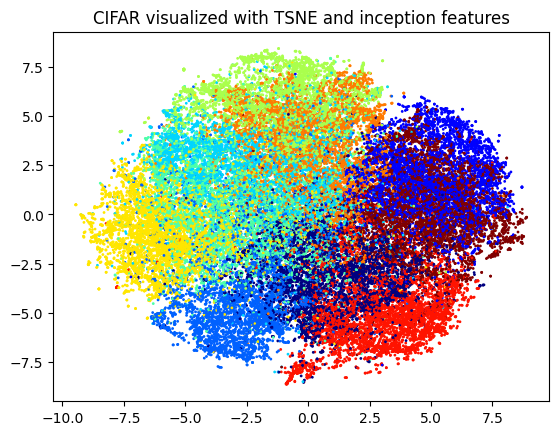

In [4]:
# TSNE
from sklearn.manifold import TSNE
start = time.time()
#tsne = TSNE(n_components=3, learning_rate='auto', init='random', perplexity=3)
#tsne = TSNE(n_components=3, verbose=1, perplexity=2, n_iter=300)
tsne = TSNE(n_components=3, verbose=1, perplexity=3, n_iter=300)
embedding = tsne.fit_transform(data_feat)
print('time(sec):',(time.time()-start)/1)

print(embedding.shape)
Xvis = embedding[:,0]
Yvis = embedding[:,1]
Zvis = embedding[:,2]

# 2D Visualization
plt.figure(3)
plt.scatter(Xvis, Yvis, c=C, s=1, color=pyplot.jet())
plt.title('CIFAR visualized with TSNE and inception features') 
plt.show()


In [5]:
# 3D Visualization
import plotly.graph_objects as go
data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1)) # data as points
# data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1, showscale=True)) # w/ colobar 
fig = go.Figure(data=[data]) 
fig.update_layout(margin=dict(l=0, r=0, b=0, t=25, pad=0)) # tight layout but t=25 required for showing title 
fig.update_layout(autosize=False, width=800, height=800, title_text="CIFAR visualized with TSNE and inception features") # figure size and title
# fig.update_layout(scene = dict(xaxis = dict(visible=False), yaxis = dict(visible=False), zaxis = dict(visible=False))) # no grid, no axis 
# fig.update_layout(scene = dict(xaxis_title = ' ', yaxis_title = ' ', zaxis_title = ' ')) # no axis name 
fig.update_layout(scene = dict(zaxis = dict(showgrid = True, showticklabels = False), zaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(yaxis = dict(showgrid = True, showticklabels = False), yaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(xaxis = dict(showgrid = True, showticklabels = False), xaxis_title = ' ') ) # no range values, no axis name, grid on
fig.show()


torch.Size([50000])
size_x, size_y: 1632 1632
max_range_x, max_range_y: tensor(8.8942) tensor(8.4331)
torch.Size([3, 1632, 1632])


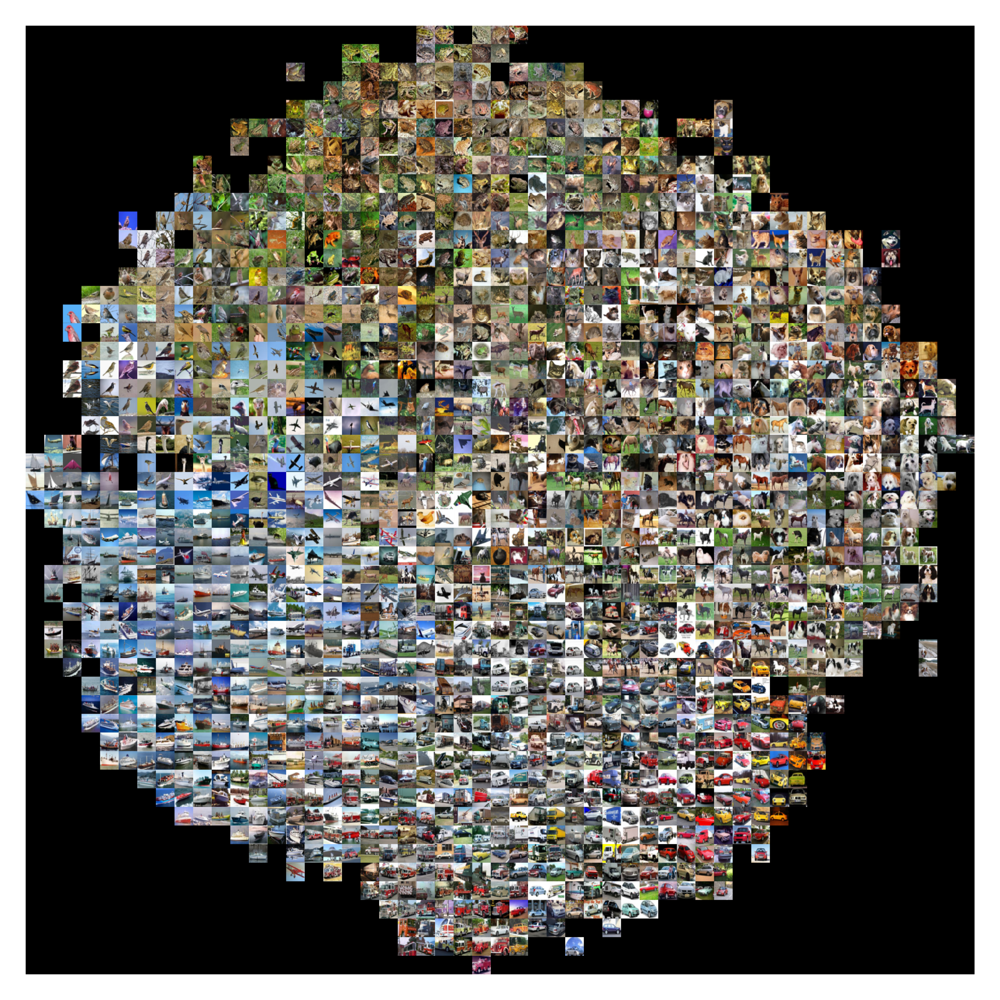

In [6]:
# Create mosaic of images with TSNE
X2d = torch.Tensor(Xvis)
print(X2d.size())
Y2d = torch.Tensor(Yvis)
num_max_image_x = 50 # 10 debug
num_max_image_y = 50
size_image_x = 32
size_image_y = 32
size_x = int( num_max_image_x * size_image_x ) + size_image_x
size_y = int( num_max_image_y * size_image_y ) + size_image_y
print('size_x, size_y:',size_x, size_y)
max_range_x = torch.max(X2d)
max_range_y = torch.max(Y2d)
min_range_x = torch.min(X2d)
min_range_y = torch.min(Y2d)
print('max_range_x, max_range_y:',max_range_x, max_range_y)
mosaic = torch.zeros(3, size_x, size_y)
print(mosaic.size())
for idx, (x_data, y_data) in enumerate(zip(X2d,Y2d)):
    idx_x_data = ( int( (x_data-min_range_x)/ (max_range_x-min_range_x) * num_max_image_x * size_image_x ) // size_image_x ) * size_image_x
    idx_y_data = ( int( (y_data-min_range_y)/ (max_range_y-min_range_y) * num_max_image_y * size_image_y ) // size_image_y ) * size_image_y
    mosaic[:, idx_x_data:idx_x_data+size_image_x, idx_y_data:idx_y_data+size_image_y] = X[idx,:,:,:]

from IPython.display import set_matplotlib_formats
set_matplotlib_formats('png2x','pdf')
plt.figure(dpi=600)
plt.imshow( np.transpose(  mosaic.numpy() , (1, 2, 0))  )
plt.axis('off')
plt.savefig('mosaic_cifar_60000_tsne.pdf')
plt.show()


# Visualize with UMAP 

UMAP(n_components=3, verbose=True)
Mon Sep 14 01:50:45 2026 Construct fuzzy simplicial set
Mon Sep 14 01:50:45 2026 Finding Nearest Neighbors
Mon Sep 14 01:50:45 2026 Building RP forest with 16 trees
Mon Sep 14 01:50:49 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	 4  /  16
	 5  /  16
	Stopping threshold met -- exiting after 5 iterations
Mon Sep 14 01:50:56 2026 Finished Nearest Neighbor Search
Mon Sep 14 01:50:57 2026 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Mon Sep 14 01:51:07 2026 Finished embedding
time(sec): 22.608220100402832
(50000, 3)


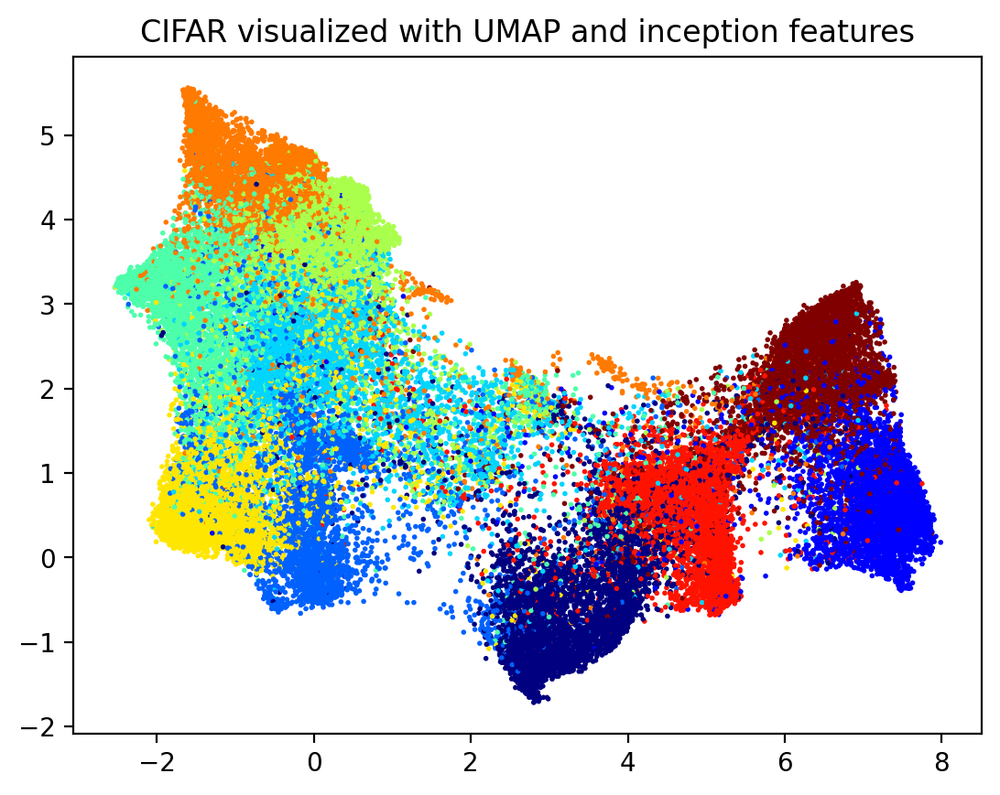

In [7]:
start = time.time()
reducer = umap.UMAP(n_components=3, verbose=True)
#reducer = umap.UMAP(n_components=2, verbose=True)
embedding = reducer.fit_transform(data_feat)
print('time(sec):',(time.time()-start)/1)

print(embedding.shape)
Xvis = embedding[:,0]
Yvis = embedding[:,1]
Zvis = embedding[:,2]

# 2D Visualization
plt.figure(3)
plt.scatter(Xvis, Yvis, c=C, s=1, color=pyplot.jet())
plt.title('CIFAR visualized with UMAP and inception features') 
plt.show()


In [8]:
# 3D Visualization
import plotly.graph_objects as go
data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1)) # data as points
# data = go.Scatter3d(x=Xvis, y=Yvis, z=Zvis, mode='markers', marker=dict(size=1, color=C, colorscale='jet', opacity=1, showscale=True)) # w/ colobar 
fig = go.Figure(data=[data]) 
fig.update_layout(margin=dict(l=0, r=0, b=0, t=25, pad=0)) # tight layout but t=25 required for showing title 
fig.update_layout(autosize=False, width=800, height=800, title_text="CIFAR visualized with UMAP and inception features") # figure size and title
# fig.update_layout(scene = dict(xaxis = dict(visible=False), yaxis = dict(visible=False), zaxis = dict(visible=False))) # no grid, no axis 
# fig.update_layout(scene = dict(xaxis_title = ' ', yaxis_title = ' ', zaxis_title = ' ')) # no axis name 
fig.update_layout(scene = dict(zaxis = dict(showgrid = True, showticklabels = False), zaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(yaxis = dict(showgrid = True, showticklabels = False), yaxis_title = ' ') ) # no range values, no axis name, grid on
fig.update_layout(scene = dict(xaxis = dict(showgrid = True, showticklabels = False), xaxis_title = ' ') ) # no range values, no axis name, grid on
fig.show()


torch.Size([50000])
size_x, size_y: 1632 1632
max_range_x, max_range_y: tensor(7.9868) tensor(5.5587)
torch.Size([3, 1632, 1632])


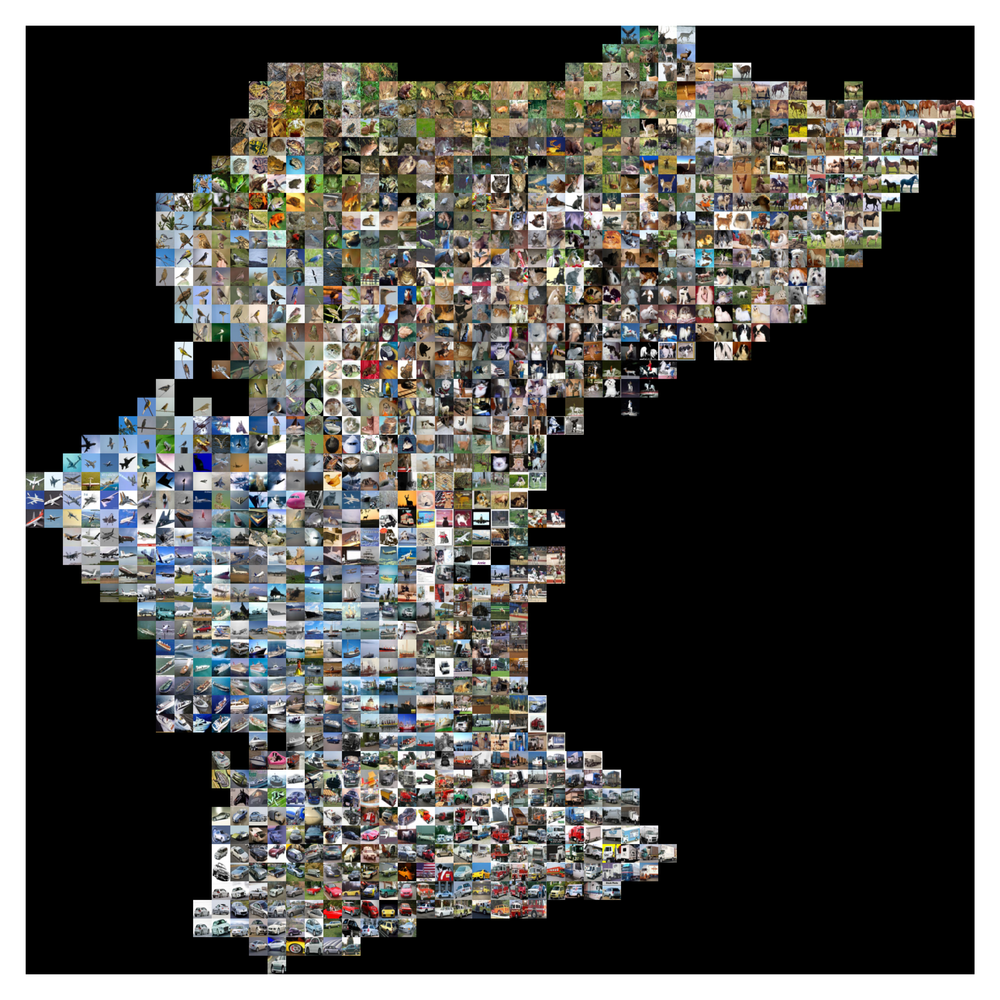

In [9]:
# Create mosaic of images with UMAP
X2d = torch.Tensor(Xvis)
print(X2d.size())
Y2d = torch.Tensor(Yvis)
num_max_image_x = 50 # 10 debug
num_max_image_y = 50
size_image_x = 32
size_image_y = 32
size_x = int( num_max_image_x * size_image_x ) + size_image_x
size_y = int( num_max_image_y * size_image_y ) + size_image_y
print('size_x, size_y:',size_x, size_y)
max_range_x = torch.max(X2d)
max_range_y = torch.max(Y2d)
min_range_x = torch.min(X2d)
min_range_y = torch.min(Y2d)
print('max_range_x, max_range_y:',max_range_x, max_range_y)
mosaic = torch.zeros(3, size_x, size_y)
print(mosaic.size())
for idx, (x_data, y_data) in enumerate(zip(X2d,Y2d)):
    idx_x_data = ( int( (x_data-min_range_x)/ (max_range_x-min_range_x) * num_max_image_x * size_image_x ) // size_image_x ) * size_image_x
    idx_y_data = ( int( (y_data-min_range_y)/ (max_range_y-min_range_y) * num_max_image_y * size_image_y ) // size_image_y ) * size_image_y
    mosaic[:, idx_x_data:idx_x_data+size_image_x, idx_y_data:idx_y_data+size_image_y] = X[idx,:,:,:]

from IPython.display import set_matplotlib_formats
set_matplotlib_formats('png2x','pdf')
plt.figure(dpi=600)
plt.imshow( np.transpose(  mosaic.numpy() , (1, 2, 0))  )
plt.axis('off')
plt.savefig('mosaic_cifar_60000_umap.pdf')
plt.show()
